# Summary of Satiation Rating Analysis

This notebook analyzes participants’ self-reported hunger, satiety, and desire-to-eat ratings collected immediately before and after the meal. Across all three measures, participants showed strong and expected changes following food consumption: hunger and desire-to-eat ratings decreased substantially, whereas satiety ratings increased. All pre–post differences were statistically significant (Wilcoxon signed-rank tests, p < 0.001), confirming that the meal effectively altered participants’ subjective satiation state.


In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy.stats import wilcoxon
import numpy as np

# load common plot configurations
from plot_config import FIG_DOUBLE, session_colors

In [59]:
base_path = Path('/Users/liuq13/project-SPCD/beh_raw/')
all_data = []

for sub_dir in base_path.glob('sub-*'):
    summary_file = sub_dir / 'ratings' / 'hunger_ratings.csv'
    if summary_file.exists():
        df = pd.read_csv(summary_file, header=None)

        # new columns
        df['question'] = (df[0] % 3) + 1
        df['phase'] = df[0].apply(lambda x: 'pre' if x < 3 else 'post')

        df['subject'] = sub_dir.name
        all_data.append(df)

combined_df = pd.concat(all_data, ignore_index=True)
combined_df = combined_df.drop(columns=[0]).rename(columns={1: "rating"})

EXCLUDE_SUBJECTS = ['sub-19', 'sub-33']
combined_df = combined_df[~combined_df['subject'].isin(EXCLUDE_SUBJECTS)]

In [60]:
# Ensure phase has a fixed order: pre, then post
phase_order = ['pre', 'post']
combined_df['phase'] = pd.Categorical(
    combined_df['phase'], categories=phase_order, ordered=True
)

In [61]:
titles = {
    1: "Current hunger level",
    2: "Current satiety level",
    3: "Current desire to eat",
}


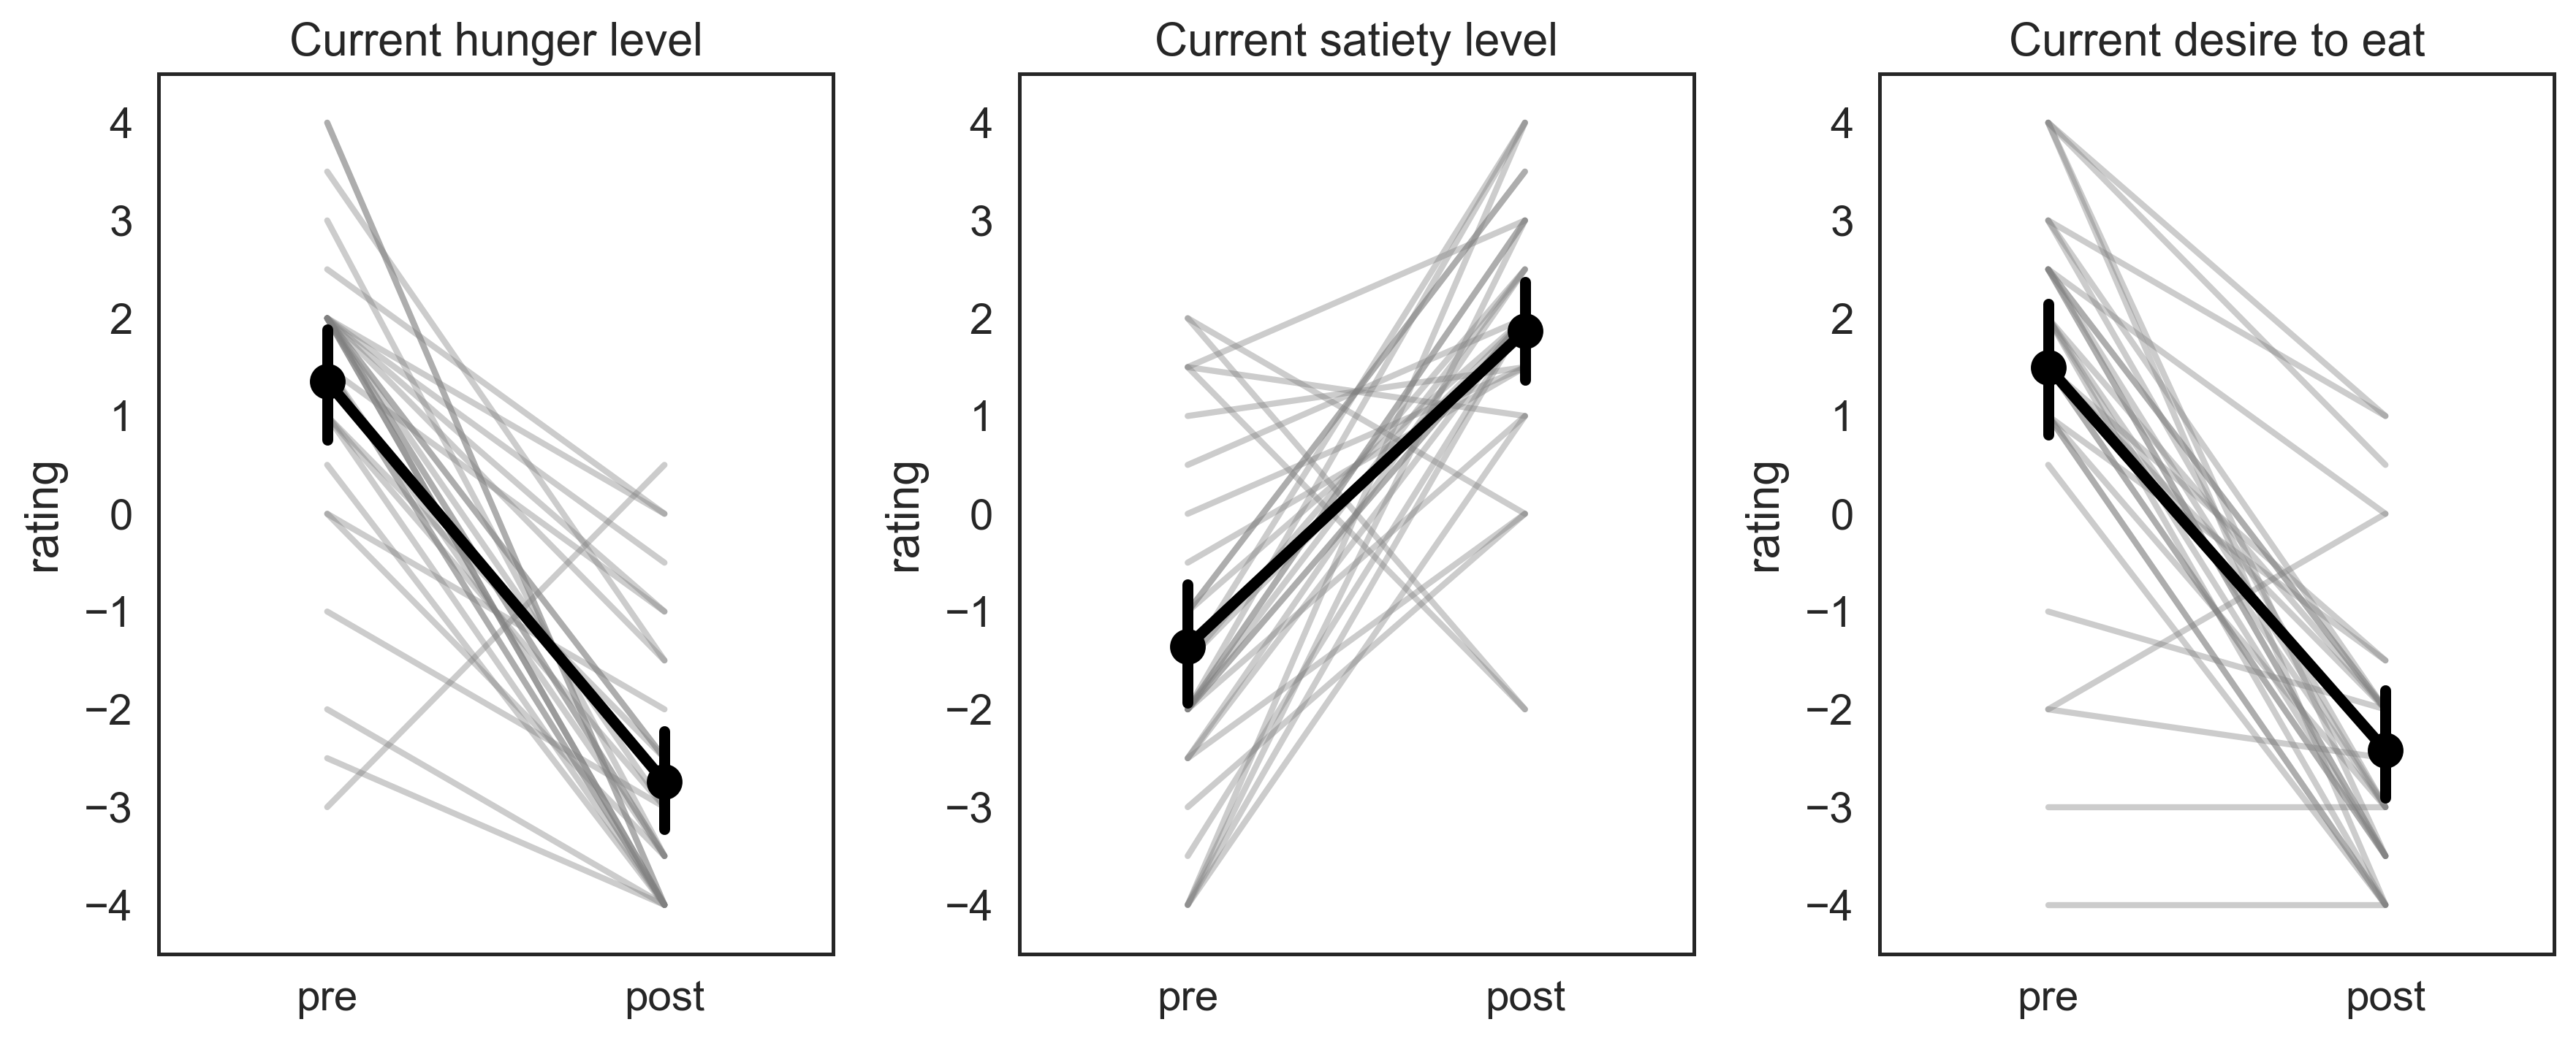

In [62]:
plt.figure(figsize=FIG_DOUBLE)

for i, q in enumerate([1, 2, 3], 1):
    ax = plt.subplot(1, 3, i)
    df_q = combined_df[combined_df["question"] == q]

    # paired lines
    for s, d in df_q.groupby("subject"):
        d = d.sort_values("phase")
        ax.plot(d["phase"], d["rating"], color="gray", alpha=0.4)

    # mean ± CI
    sns.pointplot(
        data=df_q,
        x="phase",
        y="rating",
        order=phase_order,
        color="black",
        errorbar="ci",
        ax=ax
    )

    ax.set_title(titles[q])
    ax.set_xlabel("")
    ax.set_ylabel("rating")

    ax.set_ylim(
        combined_df["rating"].min() - 0.5,
        combined_df["rating"].max() + 0.5
    )

plt.tight_layout()
plt.savefig('../plots/hungry_ratings.pdf', format='pdf', bbox_inches='tight')
plt.show()


In [63]:
results = {}

for q in [1, 2, 3]:
    df_q = combined_df[combined_df["question"] == q]

    # Get pre and post aligned by subject
    pre = df_q[df_q["phase"] == "pre"].sort_values("subject")["rating"].values
    post = df_q[df_q["phase"] == "post"].sort_values("subject")["rating"].values

    # Means
    mean_pre = np.mean(pre)
    mean_post = np.mean(post)

    # Wilcoxon signed-rank test (nonparametric paired)
    stat, p = wilcoxon(pre, post, alternative="two-sided", mode="approx")

    results[q] = {
        "statistic": stat,
        "p_value": p,
        "mean_pre": mean_pre,
        "mean_post": mean_post,
        "diff": mean_post - mean_pre
    }

# Print nicely
for q, res in results.items():
    print(f"\nQuestion {q}:")
    print(f"  Mean pre-meal:  {res['mean_pre']:.3f}")
    print(f"  Mean post-meal: {res['mean_post']:.3f}")
    print(f"  Change (post - pre): {res['diff']:.3f}")
    print(f"  Wilcoxon statistic = {res['statistic']:.3f},  p = {res['p_value']:.6f}")



Question 1:
  Mean pre-meal:  1.355
  Mean post-meal: -2.742
  Change (post - pre): -4.097
  Wilcoxon statistic = 11.500,  p = 0.000003

Question 2:
  Mean pre-meal:  -1.355
  Mean post-meal: 1.871
  Change (post - pre): 3.226
  Wilcoxon statistic = 36.000,  p = 0.000032

Question 3:
  Mean pre-meal:  1.500
  Mean post-meal: -2.419
  Change (post - pre): -3.919
  Wilcoxon statistic = 3.500,  p = 0.000004
